In [1]:
import sys
print(sys.executable)

d:\DEV\Graph Hacks\venv\Scripts\python.exe


In [2]:
import os
import json
from pathlib import Path
from typing import TypedDict, Literal

import requests
from dotenv import load_dotenv
from pydantic import BaseModel, Field

from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults

from langgraph.graph import StateGraph, START, END

C:\Users\sunil bishnoi\AppData\Local\Temp\ipykernel_13564\4121233399.py:12: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools.tavily_search import TavilySearchResults


In [3]:
MODEL_NAME = os.getenv("OPENAI_MODEL", "gpt-4.1-mini")
WEATHER_UNITS = os.getenv("WEATHER_UNITS", "metric")

In [4]:
llm = ChatOpenAI(
    model=MODEL_NAME,
    temperature=0.7,
    timeout=45,
    max_retries=2,
)

In [5]:
# Define th Pydentic Model or Structured Output
class IntentClassification(BaseModel):
    """Classifies a request and extracts routing information."""
    intent: Literal["research", "weather", "trip", "general"]
    destination: str | None = None
    duration_days: int | None = Field(
        default=None,
        ge=1,
        le=30,
    )
    needs_weather: bool = False
    reasoning: str


class ResearchSource(BaseModel):
    title: str
    url: str
    summary: str = ""


class ResearchResult(BaseModel):
    query: str
    findings: str
    sources: list[ResearchSource] = Field(default_factory=list)
    status: Literal["success", "failed"] = "success"
    error: str | None = None


class WeatherResult(BaseModel):
    city: str
    temperature: float | None = None
    feels_like: float | None = None
    humidity: int | None = None
    conditions: str | None = None
    wind_speed: float | None = None
    units: str = "metric"
    status: Literal["success", "failed"] = "success"
    error: str | None = None


class ItineraryDay(BaseModel):
    day: int = Field(ge=1)
    activities: list[str]
    notes: list[str] = Field(default_factory=list)


class ItineraryPlan(BaseModel):
    destination: str
    duration_days: int = Field(ge=1, le=30)
    days: list[ItineraryDay]
    estimated_budget: str | None = None
    assumptions: list[str] = Field(default_factory=list)
    source_urls: list[str] = Field(default_factory=list)


class ReviewResult(BaseModel):
    approved: bool
    final_answer: str
    issues: list[str] = Field(default_factory=list)
    corrections: list[str] = Field(default_factory=list)

In [ ]:
#Define the State of the Graph:
class AgentState(TypedDict, total=False):
    # Original user input
    user_query: str

    # Supervisor classification
    classification: IntentClassification

    # Specialist outputs
    research: ResearchResult
    weather: WeatherResult
    itinerary: ItineraryPlan
    review: ReviewResult

    # General requests and final output
    general_answer: str
    final_answer: str

    # Error tracking
    errors: list[str]
    revision_count: int

In [7]:
#Initalize Tools:
#Research Tool
tavily_tool = TavilySearchResults(max_results=5)

#Weater Tool
@tool
def get_weather(city: str) -> str:
    """Get current weather for a city, e.g. Jaipur,IN."""

    response = requests.get(
        "https://api.openweathermap.org/data/2.5/weather",
        params={
            "q": city,
            "appid": os.environ["OPENWEATHER_API_KEY"],
            "units": WEATHER_UNITS,
        },
        timeout=20,
    )

    response.raise_for_status()
    data = response.json()

    main = data["main"]
    conditions = data["weather"][0]

    result = {
        "city": data["name"],
        "temperature": main["temp"],
        "feels_like": main["feels_like"],
        "humidity": main["humidity"],
        "conditions": conditions["description"],
        "wind_speed": data.get("wind", {}).get("speed"),
        "units": WEATHER_UNITS,
    }

    return json.dumps(result)

C:\Users\sunil bishnoi\AppData\Local\Temp\ipykernel_13564\287617028.py:3: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tavily_tool = TavilySearchResults(max_results=5)


In [8]:
#Supervisor classification node:
def classify_request(state: AgentState) -> dict:
    classifier = llm.with_structured_output(IntentClassification)
    result = classifier.invoke([
        (
            "system",
            """
            Classify the user's request into exactly one category:

            research: asks for researched information or facts.
            weather: asks for current weather conditions.
            trip: asks for a travel itinerary or trip plan.
            general: requests unrelated to those categories.

            Extract a destination and duration when specified.
            Set needs_weather=True when weather information is
            relevant to the request, especially for trip planning.

            Do not invent missing details. If the user asks for a
            future trip, do not confuse current weather with a
            forecast for the travel dates.
            """
        ),
        ("human", state["user_query"]),
    ])
    return {"classification": result}

In [9]:
#Research Node:
def research_node(state: AgentState) -> dict:
    query = state["user_query"]

    try:
        raw_results = tavily_tool.invoke({"query": query})

        if not raw_results:
            raise ValueError("Tavily returned no search results.")

        structured_research = llm.with_structured_output(
            ResearchResult
        )

        result = structured_research.invoke([
            (
                "system",
                """
                You are the Research Agent.

                Summarize the supplied search results into a useful,
                evidence-based report.

                Only include source URLs and titles present in the
                supplied search results. Do not invent URLs or claim
                a source confirms something it does not.

                If evidence is incomplete, explain the uncertainty.
                """
            ),
            (
                "human",
                f"User request:\n{query}\n\n"
                f"Search results:\n"
                f"{json.dumps(raw_results, ensure_ascii=False, default=str)}"
            ),
        ])

        result.status = "success"

        return {"research": result}

    except Exception as exc:
        error_result = ResearchResult(
            query=query,
            findings="Research could not be completed.",
            status="failed",
            error=str(exc),
        )

        return {
            "research": error_result,
            "errors": state.get("errors", []) + [
                f"Research failed: {exc}"
            ],
        }

In [10]:
#Define THe Weather Node:
def weather_node(state: AgentState) -> dict:
    classification = state["classification"]
    city = classification.destination

    if not city:
        result = WeatherResult(
            city="Unknown",
            status="failed",
            error=(
                "No city was identified. Please specify a city "
                "for current weather information."
            ),
        )

        return {"weather": result}


    try:
        raw_result = get_weather.invoke({"city": city})
        weather_data = json.loads(raw_result)
        result = WeatherResult.model_validate(weather_data)

        return {"weather": result}

    except Exception as exc:
        result = WeatherResult(
            city=city,
            status="failed",
            error=str(exc),
        )

        return {
            "weather": result,
            "errors": state.get("errors", []) + [
                f"Weather request failed: {exc}"
            ],
        }

In [11]:
#Define The Trip Planner Node:
def planner_node(state: AgentState) -> dict:
    classification = state["classification"]
    destination = (
        classification.destination or "Not specified"
    )

    duration = classification.duration_days or 1

    research = state.get("research")
    weather = state.get("weather")

    planner = llm.with_structured_output(ItineraryPlan)

    research_data = (
        research.model_dump_json()
        if research else "Research not available."
    )

    weather_data = (
        weather.model_dump_json()
        if weather else "Weather was not requested."
    )

    result = planner.invoke([
        (
            "system",
            """
            You are the Trip Planner Agent.

            Produce a practical itinerary using the user request
            and the evidence supplied.

            Rules:
            - Return the requested number of days when known.
            - Include activities in a sensible order.
            - Use supplied research URLs only.
            - Do not invent exact prices, opening hours, bookings,
              availability, or weather forecasts.
            - Label budget figures as estimates when appropriate.
            - If weather data describes current conditions, do not
              treat it as a forecast for future travel dates.
            - Record important assumptions and missing information.
            """
        ),
        (
            "human",
            f"User request:\n{state['user_query']}\n\n"
            f"Destination: {destination}\n"
            f"Duration: {duration} days\n\n"
            f"Research data:\n{research_data}\n\n"
            f"Weather data:\n{weather_data}"
        ),
    ])

    return {"itinerary": result}

In [12]:
#Define THe Reviewer Node:
def reviewer_node(state: AgentState) -> dict:
    reviewer = llm.with_structured_output(ReviewResult)
    itinerary = state["itinerary"]
    research = state.get("research")
    weather = state.get("weather")

    result = reviewer.invoke([
        (
            "system",
            """
            You are the Reviewer Agent.

            Review the proposed itinerary against the evidence provided.

            Check for:
            - Unsupported facts and fabricated source URLs
            - Conflicts between research and weather data
            - Unrealistic itinerary sequencing
            - Unsupported exact prices or opening hours
            - Confusion between current weather and forecasts

            Correct issues where possible. Do not invent facts.

            Return a concise, polished final answer. If information
            cannot be verified, qualify the claim or explain the gap.
            """
        ),
        (
            "human",
            f"Original request:\n{state['user_query']}\n\n"
            f"Itinerary:\n{itinerary.model_dump_json()}\n\n"
            f"Research:\n"
            f"{research.model_dump_json() if research else 'None'}\n\n"
            f"Weather:\n"
            f"{weather.model_dump_json() if weather else 'None'}"
        ),
    ])

    return {"review": result}

In [13]:
#General Response Node:
def general_node(state: AgentState) -> dict:

    response = llm.invoke(state["user_query"])

    return {"general_answer": response.content}

In [14]:
## Defining The Routing Functions:
def route_after_classification(state: AgentState) -> Literal["research", "weather", "general"]:
    intent = state["classification"].intent

    if intent == "research":
        return "research"

    if intent == "weather":
        return "weather"

    if intent == "trip":
        return "research" #trip request Start with research

    return "general"


def route_after_research(state: AgentState) -> Literal["weather", "planner", "final"]:
    classification = state["classification"]

    if classification.intent != "trip":
        return "final"

    if classification.needs_weather:
        return "weather"

    return "planner"


def route_after_weather(state: AgentState) -> Literal["planner", "final"]:
    if state["classification"].intent == "trip":
        return "planner"
    return "final"

In [15]:
def final_node(state: AgentState) -> dict:
    classification = state["classification"]
    if state.get("review"):
        answer = state["review"].final_answer

    elif classification.intent == "research":
        research = state.get("research")

        if not research or research.status != "success":
            error = research.error if research else "No research result."
            answer = f"Research could not be completed. {error}"
        else:
            sources_text = "\n".join(
                f"- [{source.title}]({source.url})"
                for source in research.sources
            )

            answer = research.findings

            if sources_text:
                answer += "\n\nSources:\n" + sources_text

    elif classification.intent == "weather":
        weather = state.get("weather")

        if not weather or weather.status != "success":
            error = weather.error if weather else "No weather result."
            answer = f"Weather could not be retrieved. {error}"
        else:
            unit = {
                "metric": "°C",
                "imperial": "°F",
                "standard": "K",
            }.get(weather.units, "")

            answer = (
                f"Current weather in {weather.city}\n\n"
                f"- Temperature: {weather.temperature}{unit}\n"
                f"- Feels like: {weather.feels_like}{unit}\n"
                f"- Humidity: {weather.humidity}%\n"
                f"- Conditions: {weather.conditions}\n"
                f"- Wind speed: {weather.wind_speed}"
            )

    else:
        answer = state.get(
            "general_answer",
            "No response was generated.",
        )
    return {"final_answer": answer}

In [16]:
#Build The GRAPH:
workflow = StateGraph(AgentState)

# Register nodes
workflow.add_node("classify", classify_request)
workflow.add_node("research", research_node)
workflow.add_node("weather", weather_node)
workflow.add_node("planner", planner_node)
workflow.add_node("reviewer", reviewer_node)
workflow.add_node("general", general_node)
workflow.add_node("final", final_node)

workflow.add_edge(START, "classify")

# Supervisor routing
workflow.add_conditional_edges(
    "classify",
    route_after_classification,
    {
        "research": "research",
        "weather": "weather",
        "general": "general",
    },
)

# Research routing
workflow.add_conditional_edges(
    "research",
    route_after_research,
    {
        "weather": "weather",
        "planner": "planner",
        "final": "final",
    },
)

# Weather routing
workflow.add_conditional_edges(
    "weather",
    route_after_weather,
    {
        "planner": "planner",
        "final": "final",
    },
)

workflow.add_edge("planner", "reviewer")
workflow.add_edge("reviewer", "final")
workflow.add_edge("general", "final")
workflow.add_edge("final", END)

In [17]:
# Compile
app = workflow.compile()

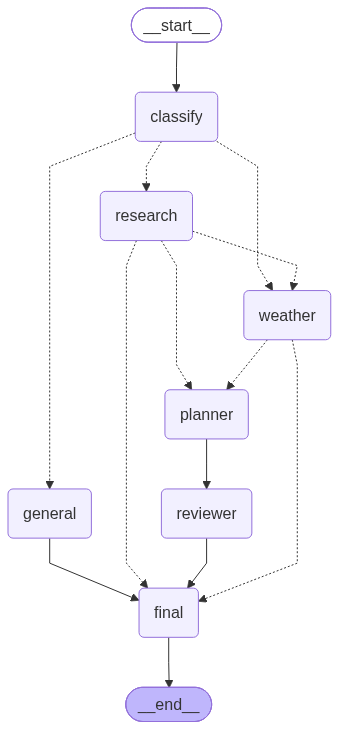

In [18]:
app

In [19]:
query1="What is the current weather in Jaipur,Rajasthan?"#weather-final
query2="Research three major tourist attractions in Jaipur, Rajasthan."#Research-final
query3="""Plan a relaxed two-day trip to Jaipur for two adults.
    Research the main attractions, consider weather when relevant,
    and create a practical itinerary with source URLs.
    Clearly distinguish current weather from a future forecast.
    """#Research-weather-planner-reviewer-final

In [20]:
result1=app.invoke({"user_query": query1})

In [21]:
print(result1)

{'user_query': 'What is the current weather in Jaipur,Rajasthan?', 'classification': IntentClassification(intent='weather', destination='Jaipur, Rajasthan', duration_days=None, needs_weather=True, reasoning='The user is asking for current weather conditions in a specific location.'), 'weather': WeatherResult(city='Jaipur', temperature=25.63, feels_like=26.21, humidity=75, conditions='overcast clouds', wind_speed=3.66, units='metric', status='success', error=None), 'final_answer': 'Current weather in Jaipur\n\n- Temperature: 25.63°C\n- Feels like: 26.21°C\n- Humidity: 75%\n- Conditions: overcast clouds\n- Wind speed: 3.66'}


In [22]:
print(result1["user_query"])

What is the current weather in Jaipur,Rajasthan?


In [23]:
print(result1["classification"])

intent='weather' destination='Jaipur, Rajasthan' duration_days=None needs_weather=True reasoning='The user is asking for current weather conditions in a specific location.'


In [24]:
print(result1["weather"])

city='Jaipur' temperature=25.63 feels_like=26.21 humidity=75 conditions='overcast clouds' wind_speed=3.66 units='metric' status='success' error=None


In [25]:
result2=app.invoke({"user_query": query2})

In [26]:
print(result2)

{'user_query': 'Research three major tourist attractions in Jaipur, Rajasthan.', 'classification': IntentClassification(intent='research', destination='Jaipur, Rajasthan', duration_days=None, needs_weather=False, reasoning='The user is asking for researched information about tourist attractions, which falls under the research category.'), 'research': ResearchResult(query='three major tourist attractions in Jaipur, Rajasthan', findings="The three major tourist attractions in Jaipur include:\n1. **Amer Fort**: This iconic hilltop fortress is renowned for its grand architecture, elaborate courtyards, and stunning views of the Aravalli hills, making it a significant representation of Jaipur's royal heritage.\n2. **Hawa Mahal**: Known as the 'Palace of Winds', this distinctive structure features a honeycomb facade with numerous jharokhas (balconies) and is famous for its intricate design and photogenic qualities, especially at sunrise.\n3. **City Palace**: A historic complex that blends Raj

In [27]:
print(result2["user_query"])

Research three major tourist attractions in Jaipur, Rajasthan.


In [28]:
print(result2["classification"])

intent='research' destination='Jaipur, Rajasthan' duration_days=None needs_weather=False reasoning='The user is asking for researched information about tourist attractions, which falls under the research category.'


In [29]:
print(result2["research"])

query='three major tourist attractions in Jaipur, Rajasthan' findings="The three major tourist attractions in Jaipur include:\n1. **Amer Fort**: This iconic hilltop fortress is renowned for its grand architecture, elaborate courtyards, and stunning views of the Aravalli hills, making it a significant representation of Jaipur's royal heritage.\n2. **Hawa Mahal**: Known as the 'Palace of Winds', this distinctive structure features a honeycomb facade with numerous jharokhas (balconies) and is famous for its intricate design and photogenic qualities, especially at sunrise.\n3. **City Palace**: A historic complex that blends Rajasthani and Mughal architectural styles, the City Palace is the official residence of the royal family and houses museums, courtyards, and exhibits showcasing Jaipur's history and culture." sources=[ResearchSource(title='Tourist Attractions in Jaipur | Jaipur Tourist Places', url='https://www.sawaihospitality.com/blogs/tourist-attractions-in-jaipur.html', summary='Th

In [30]:
result3=app.invoke({"user_query": query3})

In [31]:
print(result3)

{'user_query': 'Plan a relaxed two-day trip to Jaipur for two adults.\n    Research the main attractions, consider weather when relevant,\n    and create a practical itinerary with source URLs.\n    Clearly distinguish current weather from a future forecast.\n    ', 'classification': IntentClassification(intent='trip', destination='Jaipur', duration_days=2, needs_weather=True, reasoning='The user is requesting a travel itinerary for a trip to Jaipur, which involves planning attractions and considering the weather.'), 'research': ResearchResult(query='relaxed two-day trip to Jaipur', findings='Jaipur is a vibrant city filled with historical attractions, and October is an ideal month to visit due to its pleasant weather. The itinerary suggests visiting major landmarks at a comfortable pace, allowing for both sightseeing and relaxation.', sources=[ResearchSource(title='TOP 15 Things To Do & Attractions in Jaipur (October 2026)', url='https://www.viator.com/en-NZ/Jaipur/d4627', summary='A 

In [32]:
print(result3["user_query"])

Plan a relaxed two-day trip to Jaipur for two adults.
    Research the main attractions, consider weather when relevant,
    and create a practical itinerary with source URLs.
    Clearly distinguish current weather from a future forecast.
    


In [33]:
print(result3["classification"])

intent='trip' destination='Jaipur' duration_days=2 needs_weather=True reasoning='The user is requesting a travel itinerary for a trip to Jaipur, which involves planning attractions and considering the weather.'


In [34]:
print(result3["research"])

query='relaxed two-day trip to Jaipur' findings='Jaipur is a vibrant city filled with historical attractions, and October is an ideal month to visit due to its pleasant weather. The itinerary suggests visiting major landmarks at a comfortable pace, allowing for both sightseeing and relaxation.' sources=[ResearchSource(title='TOP 15 Things To Do & Attractions in Jaipur (October 2026)', url='https://www.viator.com/en-NZ/Jaipur/d4627', summary='A good way to spend a day in Jaipur is by getting up early and going to the nearby Amber Fort before the temperatures get too hot.'), ResearchSource(title='Jaipur Weather in October 2026 - Temperature & Climate', url='https://www.makemytrip.com/tripideas/jaipur/jaipur-weather-in-october', summary='October in Jaipur marks the arrival of autumn, bringing cooler temperatures and clear skies. Jaipur temperature in October ranges between approximately 19.7C to 32.9C, creating a favourable environment for visitors.'), ResearchSource(title='10 TOP Things 

In [35]:
print(result3["weather"])

city='Jaipur' temperature=25.78 feels_like=26.11 humidity=65 conditions='overcast clouds' wind_speed=3.66 units='metric' status='success' error=None


In [37]:
print(result3["itinerary"])

destination='Jaipur' duration_days=2 days=[ItineraryDay(day=1, activities=['Visit Amber Fort early in the morning to avoid crowds and heat.', 'Explore the beautiful Hawa Mahal, also known as the Palace of Winds.', 'Lunch at a local restaurant to enjoy traditional Rajasthani cuisine.', 'Visit the City Palace, a stunning blend of Mughal and Rajput architecture.', 'Stroll around Johri Bazaar for some shopping and local handicrafts.'], notes=['Start early to enjoy the attractions before it gets too warm.', 'Wear comfortable shoes as there will be a lot of walking.']), ItineraryDay(day=2, activities=['Morning visit to Jal Mahal, a picturesque water palace.', 'Explore Nahargarh Fort for panoramic views of the city.', 'Lunch at a café in the area.', 'Visit Birla Mandir Temple to admire its beautiful architecture.', 'Relax at a local park or café before departure.'], notes=['Consider spending a leisurely afternoon taking in the views from Nahargarh Fort.'])] estimated_budget='Estimated budget 

In [39]:
print(result3["review"])

approved=False final_answer='The proposed itinerary for a two-day trip to Jaipur is overall well-structured, but there are several issues that need to be addressed regarding unsupported facts, potential conflicts with weather data, and lack of verified sources.\n\n### Issues:\n1. **Unsupported Source URLs:** The URLs provided in the itinerary do not correspond to the specific claims made in the itinerary. For instance, there is no evidence from the provided sources to confirm the exact prices or opening hours for the attractions mentioned.\n2. **Weather Confusion:** The itinerary states that the travel is assumed in October based on the weather data, but it fails to clarify whether the current weather conditions (25.78°C with overcast clouds) are representative of the expected conditions for the entire month or just for one day.\n3. **Unrealistic Sequencing:** The itinerary suggests visiting Amber Fort early in the morning and then Hawa Mahal, City Palace, etc., but does not account fo

In [40]:
print(result3["final_answer"])

The proposed itinerary for a two-day trip to Jaipur is overall well-structured, but there are several issues that need to be addressed regarding unsupported facts, potential conflicts with weather data, and lack of verified sources.

### Issues:
1. **Unsupported Source URLs:** The URLs provided in the itinerary do not correspond to the specific claims made in the itinerary. For instance, there is no evidence from the provided sources to confirm the exact prices or opening hours for the attractions mentioned.
2. **Weather Confusion:** The itinerary states that the travel is assumed in October based on the weather data, but it fails to clarify whether the current weather conditions (25.78°C with overcast clouds) are representative of the expected conditions for the entire month or just for one day.
3. **Unrealistic Sequencing:** The itinerary suggests visiting Amber Fort early in the morning and then Hawa Mahal, City Palace, etc., but does not account for the travel time between these lo